
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/12_Lab_PinnsI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pylab as plt
import numpy as np
import matplotlib.pyplot as plt

#Diferenciación automática

In [2]:
def suma(a, da, b, db):
  return a+b, da+db

def producto(a, da, b, db):
  return a*b, a*db + da*b

def division(a, da, b, db):
  return a/b, (b*da - a*db)/(b**2)

def seno(a, da):
  return np.sin(a), da*np.cos(a)

def coseno(a, da):
  return np.cos(a), -da*np.sin(a)


def tanhiperbolica(a, da):
    valor = np.tanh(a)
    return valor, (1 - valor**2)*da

Computemos la deriva de:

$f(x) = x^2$


$f(x) = (2x+1)^2$

In [3]:
x = 2.2

In [4]:
derivadaX = producto(x, 1, x, 1)
derivadaX

(4.840000000000001, 4.4)

In [5]:
u, du = producto(2, 0, x, 1)
c, dc = suma(u, du, 1, 0)
producto(c, dc, c, dc)

(29.160000000000004, 21.6)

In [6]:
x = np.linspace(0, 2*np.pi)

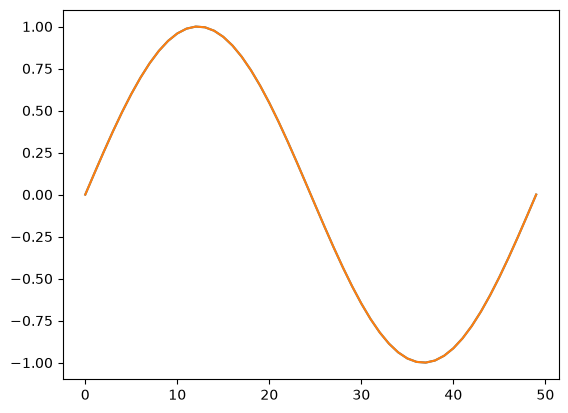

In [7]:
plt.plot(np.sin(x))
plt.plot(seno(x, 1)[0])

$
f(x)=\sin\!\bigl(\cos(x^2)\bigr),
$

$
u=x^2,\qquad u'=2x,
$

$
v=\cos(u),\qquad v'=-\sin(u)\,u',
$


$
f=\sin(v),\qquad f'=\cos(v)\,v'.
$


$
f'(x)=-2x\,\sin(x^2)\,\cos\!\bigl(\cos(x^2)\bigr).
$

In [8]:
x = np.linspace(0, 2*np.pi, 10000)
u, du = producto(x, 1, x, 1)
c, dc = coseno(u, du)
r, dr = seno(c, dc)

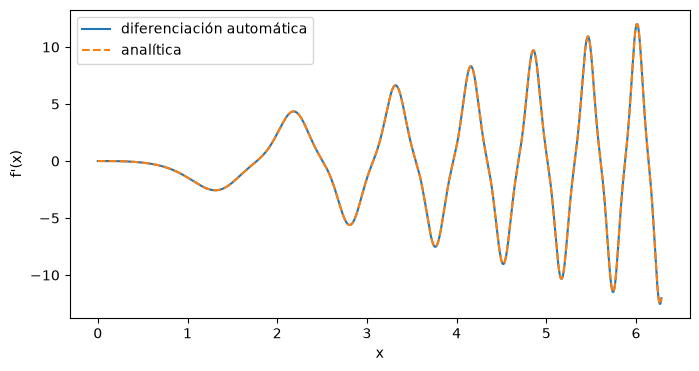

máx |AD − analítica|          = 0.0e+00
máx |np.gradient − analítica| = 1.9e-02


In [9]:
analitica = -2 * x * np.sin(x**2) * np.cos(np.cos(x**2))

plt.figure(figsize=(8, 4))
plt.plot(x, dr, label="diferenciación automática")
plt.plot(x, analitica, "--", label="analítica")
plt.xlabel("x")
plt.ylabel("f'(x)")
plt.legend()
plt.show()

print(f"máx |AD − analítica|          = {np.abs(dr - analitica).max():.1e}")
print(f"máx |np.gradient − analítica| = {np.abs(np.gradient(r, x) - analitica).max():.1e}")

En la plantilla, `seno` devolvía $\cos a$ como valor y `coseno` devolvía $-\sin a$ y $-\dot a\cos a$. Después de corregirlas a $(\sin a,\ \dot a\cos a)$ y $(\cos a,\ -\dot a\sin a)$, la diferenciación automática coincide exactamente con la derivada analítica. Con `np.gradient` queda el error de truncamiento propio de las diferencias finitas.

Supongamos que tenemos dos conectadas y queremos computar una diferenciacion automática cuyas funciones de activación son tanh:

\begin{equation}
\frac{da_2}{dx}
=
\frac{da_2}{dz_2}
\frac{dz_2}{da_1}
\frac{da_1}{dz_1}
\frac{dz_1}{dx}
=
(1-\tanh Z_2^2)\,w_2\,(1-\tanh Z_1^2)\,w_1.
\end{equation}



In [10]:
x = 0.8
w = 0.1
b = 0.1

z = w*x + b
a1 = np.tanh(z)

z2 = w*a1 + b
a2 = np.tanh(z2)

derivada = (1-(np.tanh( z2))**2) * (1-(np.tanh( z))**2)*w**2
derivada

np.float64(0.009549719627467191)

In [11]:
t1, dt1 = producto(w, 0, x, 1)
z, dz = suma(t1, dt1, b, 0)
a1, da1 = tanhiperbolica(z, dz)

t2, dt2 = producto(w, 0, a1, da1)
z2, dz2 = suma(t2, dt2, b, 0)
a2, da2 = tanhiperbolica(z2, dz2)
a2, da2




(np.float64(0.11726608605144122), np.float64(0.009549719627467191))

In [12]:
def dneurona(x, dx, w, b):
  t1, dt1 = producto(w, 0, x, dx)
  z, dz = suma(t1, dt1, b, 0)
  a1, da1 = tanhiperbolica(z, dz)
  return a1, da1

In [13]:
a1, da1 = dneurona(x, 1, w, b)
a2, da2 = dneurona(a1, da1, w, b)
a2, da2

(np.float64(0.11726608605144122), np.float64(0.009549719627467191))

### Difusión de calor en una placa cuadrada

Considere una placa homogénea de lado $L$, sin fuentes internas
de calor y con temperatura uniforme a través de su espesor.
Su difusividad térmica es constante:

$$
\alpha=\frac{k}{\rho c_p},
$$

donde $k$ es la conductividad térmica, $\rho$ la densidad y
$c_p$ el calor específico.

Determine la temperatura $T(x,y,t)$ en el dominio
$(x,y)\in(0,L)^2$, para $t>0$, mediante la ecuación de calor:

$$
\frac{\partial T}{\partial t}
=
\alpha\left(
\frac{\partial^2T}{\partial x^2}
+
\frac{\partial^2T}{\partial y^2}
\right).
$$

Los cuatro bordes permanecen a temperatura constante $T_b$:

$$
T(0,y,t)=T(L,y,t)=T(x,0,t)=T(x,L,t)=T_b.
$$

La temperatura inicial es:

$$
T(x,y,0)=T_b+\Delta T
\sin\left(\frac{\pi x}{L}\right)
\sin\left(\frac{\pi y}{L}\right),
$$

donde $\Delta T>0$ es la diferencia inicial entre la temperatura
del centro y la de los bordes.

Aproximar $T(x,y,t)$ mediante una PINN,
minimizando el residual de la ecuación y los errores en las
condiciones iniciales y de frontera. Comparar el resultado
con la solución analítica:

$$
T(x,y,t)=T_b+\Delta T
e^{-2\alpha\pi^2t/L^2}
\sin\left(\frac{\pi x}{L}\right)
\sin\left(\frac{\pi y}{L}\right).
$$

In [14]:
Lx = 1.0       # Longitud en x [m]
Ly = 1.0       # Longitud en y [m]
Tb = 300     # Temperatura fija de los bordes [°C]
delta_T = 100.0 # Diferencia inicial centro-bordes [°C]

alpha = 1e-4  # Difusividad térmica [m²/s]
params = {'Lx': Lx, 'Ly': Ly, 'Tb': Tb, "delta":delta_T ,'alpha': alpha}

In [15]:
def T(x, y, t, **params):

  Lx = params['Lx']
  Ly = params['Ly']
  Tb = params['Tb']
  alpha = params['alpha']
  u = np.sin(np.pi*x/Lx)*np.sin(np.pi*y/Ly)
  return Tb + params['delta'] * np.exp(-alpha*np.pi**2*(1/Lx**2 + 1/Ly**2)*t)*u


In [16]:
nx, ny = 30, 30
tiempo_final = 500.0

x = np.linspace(0, params["Lx"], nx)
y = np.linspace(0, params["Ly"], ny)
dx = x[1] - x[0]
dy = y[1] - y[0]

# Límite de estabilidad para diferencias finitas con Euler explícito
dt_max = 1 / (
    2 * params["alpha"] * (1 / dx**2 + 1 / dy**2)
)
# Margen de seguridad del 10 %
nt = int(np.ceil(tiempo_final / (0.9 * dt_max))) + 1

t = np.linspace(0, tiempo_final, nt)
dt = t[1] - t[0]
X, Y = np.meshgrid(x, y, indexing="ij")
nx, ny, nt = len(x), len(y), len(t)
Temperatura = np.zeros((nt,nx, ny))

### Diferencias finitas

Se usa un esquema explícito, con Euler en $t$ y diferencias centradas en $x$ e $y$, dejando los bordes fijos en $T_b$. El paso `dt` definido en la celda anterior ya está dentro del límite de estabilidad.

In [17]:
Temperatura[:] = Tb
Temperatura[0] = T(X, Y, 0, **params)
for k in range(nt - 1):
    Tk = Temperatura[k]
    laplaciano = ((Tk[2:, 1:-1] - 2 * Tk[1:-1, 1:-1] + Tk[:-2, 1:-1]) / dx**2
                  + (Tk[1:-1, 2:] - 2 * Tk[1:-1, 1:-1] + Tk[1:-1, :-2]) / dy**2)
    Temperatura[k + 1, 1:-1, 1:-1] = Tk[1:-1, 1:-1] + params["alpha"] * dt * laplaciano

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors


def graficar_planos(Temperatura, Lx, Ly, tiempos=None, n_planos=5, opacidad=0.5):
    """Planos T(x, y) en `n_planos` tiempos, incluidos el primero y el último, apilados sobre el eje temporal."""
    nt, nx, ny = Temperatura.shape
    X, Y = np.meshgrid(np.linspace(0, Lx, nx), np.linspace(0, Ly, ny), indexing="ij")

    titulo_t = "Tiempo [s]" if tiempos is not None else "Índice de tiempo"
    tiempos = np.arange(nt) if tiempos is None else np.asarray(tiempos)
    indices = np.unique(np.linspace(0, nt - 1, min(n_planos, nt), dtype=int))

    norma = colors.Normalize(np.nanmin(Temperatura), np.nanmax(Temperatura))  # escala de colores común
    mapa = plt.get_cmap("jet")

    fig = plt.figure(figsize=(9, 6))
    eje = fig.add_subplot(projection="3d")
    for k in indices:
        color = mapa(norma(Temperatura[k]))
        color[..., 3] = opacidad
        eje.plot_surface(np.full(X.shape, tiempos[k], dtype=float), X, Y, facecolors=color,
                         rstride=1, cstride=1, linewidth=0, shade=False)
    eje.set(xlabel=titulo_t, ylabel="x [m]", zlabel="y [m]")
    eje.set_box_aspect((1.6, 1, Ly / Lx))
    eje.view_init(elev=20, azim=-135)
    fig.colorbar(cm.ScalarMappable(norma, mapa), ax=eje, shrink=0.6, label="Temperatura [°C]")
    return fig

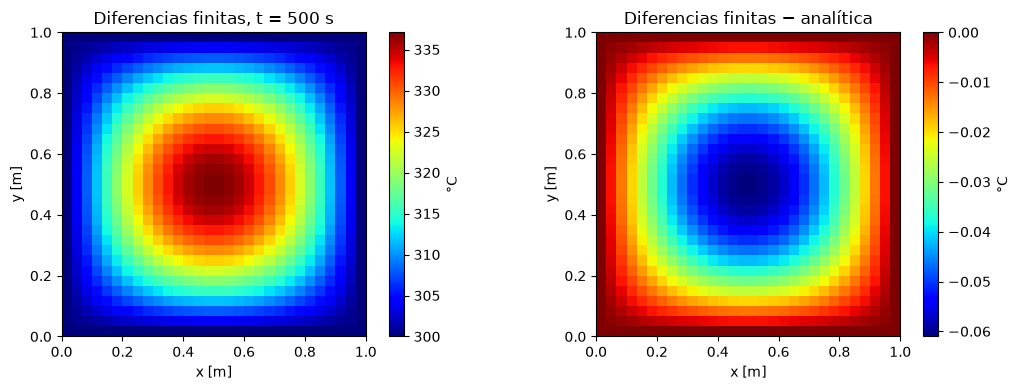

error máximo de diferencias finitas: 0.061 °C


In [19]:
Temperatura_analitica = T(X, Y, t[:, None, None], **params)
error_DF = Temperatura - Temperatura_analitica

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, campo, titulo in [(axes[0], Temperatura[-1], f"Diferencias finitas, t = {t[-1]:.0f} s"),
                          (axes[1], error_DF[-1], "Diferencias finitas − analítica")]:
    im = ax.imshow(campo.T, origin="lower", extent=[0, Lx, 0, Ly], cmap="jet")
    fig.colorbar(im, ax=ax, label="°C")
    ax.set(title=titulo, xlabel="x [m]", ylabel="y [m]")
plt.tight_layout()
plt.show()

print(f"error máximo de diferencias finitas: {np.abs(error_DF).max():.3f} °C")

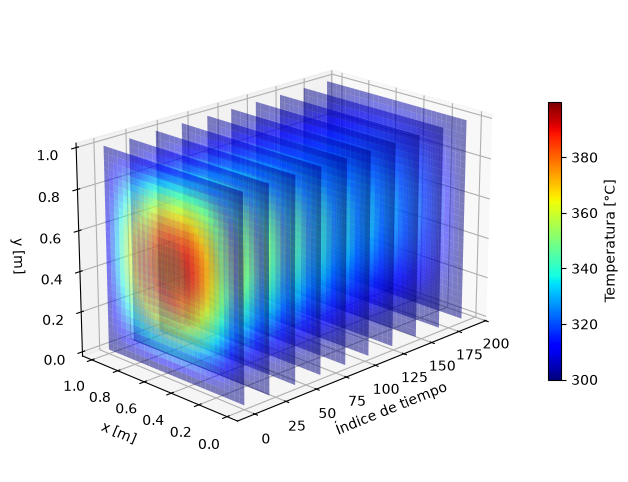

In [20]:
fig = graficar_planos(
    Temperatura, Lx, Ly,
    n_planos=10,
    opacidad=0.5
)
plt.show()

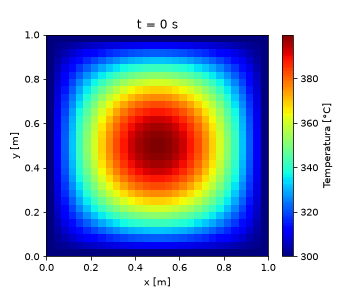

In [21]:
import tempfile
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image

fig, eje = plt.subplots(figsize=(5, 4))
imagen = eje.imshow(Temperatura[0].T, origin="lower", extent=[0, Lx, 0, Ly], cmap="jet",
                    vmin=np.nanmin(Temperatura), vmax=np.nanmax(Temperatura))
fig.colorbar(imagen, ax=eje, label="Temperatura [°C]")
eje.set(xlabel="x [m]", ylabel="y [m]")


def actualizar(k):
    imagen.set_data(Temperatura[k].T)
    eje.set_title(f"t = {t[k]:.0f} s")
    return (imagen,)


# 48 cuadros (incluidos el primero y el último), guardados como GIF: se ve en cualquier visor de notebooks
animacion = FuncAnimation(fig, actualizar, frames=np.linspace(0, nt - 1, 48, dtype=int))
with tempfile.TemporaryDirectory() as carpeta:
    animacion.save(f"{carpeta}/animacion.gif", writer=PillowWriter(fps=8), dpi=72)
    gif = Image(filename=f"{carpeta}/animacion.gif")
plt.close(fig)
gif

### PINN

Para la PINN se trabaja con las variables adimensionales $\xi=x/L_x$, $\eta=y/L_y$, $\tau=t/t_f$ y $u=(T-T_b)/\Delta T$, con las que el problema queda

$$u_\tau=\kappa_x u_{\xi\xi}+\kappa_y u_{\eta\eta},\qquad \kappa=\alpha t_f/L^2=0.05,$$

con $u=0$ en los bordes y $u(\xi,\eta,0)=\sin\pi\xi\,\sin\pi\eta$.

La red es un MLP $(\xi,\eta,\tau)\to u$ con tres capas ocultas de 32 neuronas tanh, y las derivadas del residuo se calculan con la diferenciación automática de PyTorch. La pérdida es la suma de los errores cuadráticos medios del residuo, de la condición inicial y de la condición de borde. Para optimizar se usa primero Adam, tomando puntos nuevos en cada iteración, y después L-BFGS sobre un conjunto fijo de puntos, hasta que la pérdida deja de bajar.

In [22]:
import torch

torch.manual_seed(0)
kx = params["alpha"] * tiempo_final / Lx**2
ky = params["alpha"] * tiempo_final / Ly**2

red = torch.nn.Sequential(
    torch.nn.Linear(3, 32), torch.nn.Tanh(),
    torch.nn.Linear(32, 32), torch.nn.Tanh(),
    torch.nn.Linear(32, 32), torch.nn.Tanh(),
    torch.nn.Linear(32, 1),
)


def derivada(f, p):
    return torch.autograd.grad(f, p, torch.ones_like(f), create_graph=True)[0]


def residuo(p):
    """u_τ − κx u_ξξ − κy u_ηη en los puntos p = (ξ, η, τ)."""
    p = p.clone().requires_grad_(True)
    du = derivada(red(p), p)
    u_xx = derivada(du[:, 0:1], p)[:, 0:1]
    u_yy = derivada(du[:, 1:2], p)[:, 1:2]
    return du[:, 2:3] - kx * u_xx - ky * u_yy


def puntos(n):
    """n puntos aleatorios en el interior, en τ = 0 y sobre los bordes."""
    interior = torch.rand(n, 3)
    inicial = torch.rand(n, 3) * torch.tensor([1.0, 1.0, 0.0])
    borde = torch.rand(n, 3)
    lado = torch.randint(0, 4, (n,))
    borde[lado < 2, 0] = lado[lado < 2].float()        # ξ = 0 o ξ = 1
    borde[lado >= 2, 1] = lado[lado >= 2].float() - 2  # η = 0 o η = 1
    return interior, inicial, borde


def perdidas(interior, inicial, borde):
    """[J_física, J_inicial, J_borde]"""
    u0 = torch.sin(torch.pi * inicial[:, 0:1]) * torch.sin(torch.pi * inicial[:, 1:2])
    return torch.stack([residuo(interior).pow(2).mean(),
                        (red(inicial) - u0).pow(2).mean(),
                        red(borde).pow(2).mean()])

In [23]:
historia = []

adam = torch.optim.Adam(red.parameters(), lr=1e-3)
for _ in range(3000):
    J = perdidas(*puntos(2000))
    adam.zero_grad()
    J.sum().backward()
    adam.step()
    historia.append(J.detach().numpy())

fijos = puntos(4000)
lbfgs = torch.optim.LBFGS(red.parameters(), max_iter=5000, history_size=50, line_search_fn="strong_wolfe",
                          tolerance_grad=1e-12, tolerance_change=1e-14)


def cierre():
    lbfgs.zero_grad()
    J = perdidas(*fijos)
    J.sum().backward()
    historia.append(J.detach().numpy())
    return J.sum()


lbfgs.step(cierre)
historia = np.array(historia)
print("pérdidas finales [física, inicial, borde]:", historia[-1])

pérdidas finales [física, inicial, borde]: [8.0777420e-07 1.2307530e-07 2.0854957e-07]


diferencias finitas : error máximo = 0.061 °C,  error L2 relativo a T − Tb = 7.1e-04
PINN                : error máximo = 0.367 °C,  error L2 relativo a T − Tb = 7.8e-04


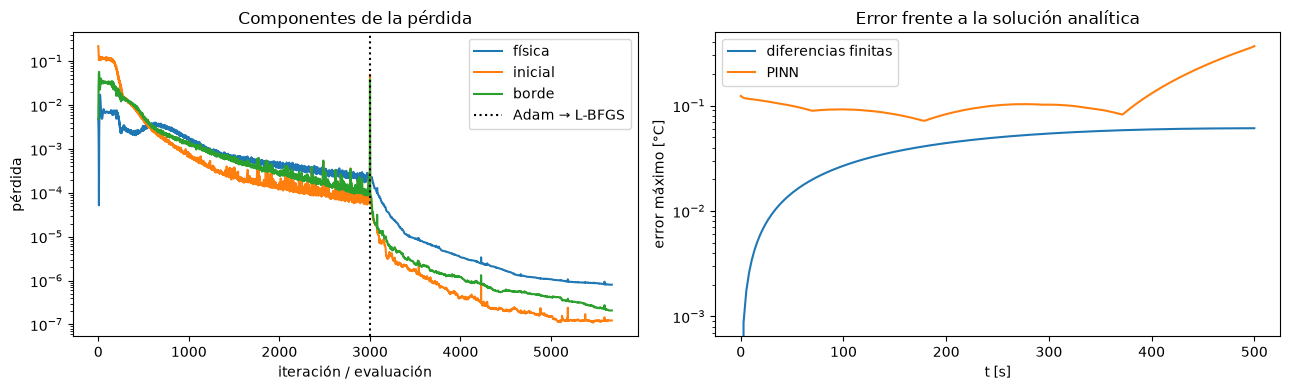

In [24]:
tau, xi, eta = np.meshgrid(t / tiempo_final, x / Lx, y / Ly, indexing="ij")
entrada = torch.tensor(np.column_stack([xi.ravel(), eta.ravel(), tau.ravel()]), dtype=torch.float32)
with torch.no_grad():
    Temperatura_PINN = Tb + params["delta"] * red(entrada).numpy().reshape(nt, nx, ny)
error_PINN = Temperatura_PINN - Temperatura_analitica

for nombre, error in [("diferencias finitas", error_DF), ("PINN", error_PINN)]:
    print(f"{nombre:20s}: error máximo = {np.abs(error).max():.3f} °C,  "
          f"error L2 relativo a T − Tb = {np.linalg.norm(error) / np.linalg.norm(Temperatura_analitica - Tb):.1e}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for k, nombre in enumerate(["física", "inicial", "borde"]):
    axes[0].semilogy(historia[:, k], label=nombre)
axes[0].axvline(3000, color="k", ls=":", label="Adam → L-BFGS")
axes[0].set(xlabel="iteración / evaluación", ylabel="pérdida", title="Componentes de la pérdida")
axes[0].legend()
axes[1].semilogy(t, np.abs(error_DF).max(axis=(1, 2)), label="diferencias finitas")
axes[1].semilogy(t, np.abs(error_PINN).max(axis=(1, 2)), label="PINN")
axes[1].set(xlabel="t [s]", ylabel="error máximo [°C]", title="Error frente a la solución analítica")
axes[1].legend()
plt.tight_layout()
plt.show()

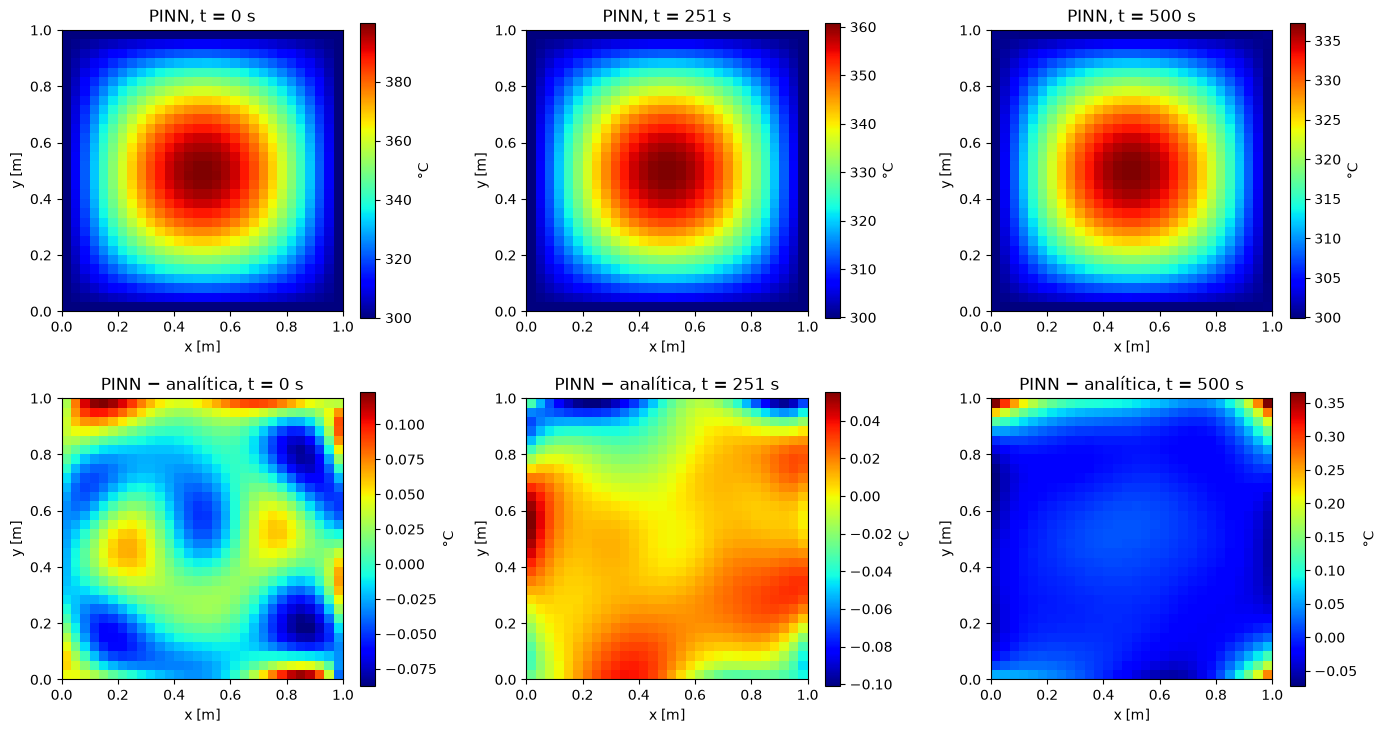

In [25]:
indices = [0, nt // 2, nt - 1]
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for j, k in enumerate(indices):
    for fila, (campo, titulo) in enumerate([(Temperatura_PINN[k], "PINN"), (error_PINN[k], "PINN − analítica")]):
        im = axes[fila, j].imshow(campo.T, origin="lower", extent=[0, Lx, 0, Ly], cmap="jet")
        fig.colorbar(im, ax=axes[fila, j], label="°C")
        axes[fila, j].set(title=f"{titulo}, t = {t[k]:.0f} s", xlabel="x [m]", ylabel="y [m]")
plt.tight_layout()
plt.show()

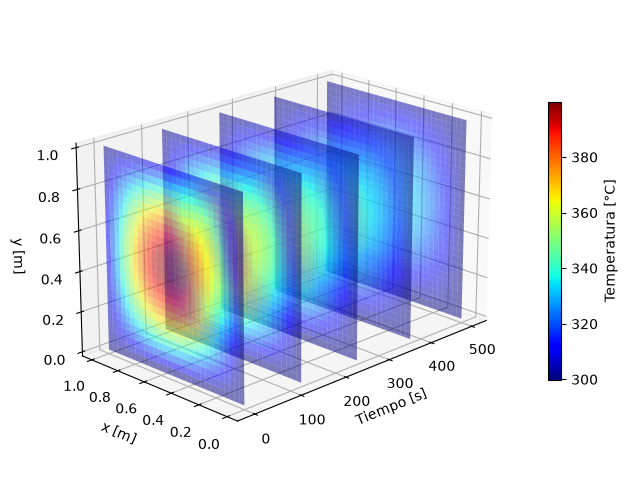

In [26]:
graficar_planos(Temperatura_PINN, Lx, Ly, tiempos=t, n_planos=5)
plt.show()

La PINN reproduce la solución analítica con un error máximo de 0.37 °C (0.4 % de $\Delta T$) y un error $L^2$ relativo de $7.8\times10^{-4}$. En la misma malla, las diferencias finitas tienen un error $L^2$ parecido ($7.1\times10^{-4}$) y un error máximo unas 6 veces menor (0.06 °C). Además tardan milisegundos, mientras que la PINN necesita alrededor de un minuto y medio de entrenamiento.

El error de la PINN se concentra en los bordes y en las esquinas, donde la condición de borde solo entra a través de la pérdida, y crece hacia $t=500$ s, que es el extremo del dominio de entrenamiento. En el error máximo la PINN pierde. Lo que sí ofrece es una solución continua y derivable en $(x,y,t)$, sin malla y sin condición de estabilidad.